In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\RAM\Downloads\cleaned_dataset.csv")

print("Cleaned dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Cleaned dataset loaded successfully!
Rows: 29531
Columns: 16


In [3]:
df.head()

,city,date,pm2.5,pm10,no,no2,nox,nh3,co,so2,o3,benzene,toluene,xylene,aqi,aqi_bucket
0,Ahmedabad,2015-01-01,48.57,95.68,0.92,18.22,17.15,15.85,0.92,27.64,133.36,0.00,0.02,0.00,118.0,Moderate
1,Ahmedabad,2015-01-02,48.57,95.68,0.97,15.69,16.46,15.85,0.97,24.55,34.06,3.68,5.50,3.77,118.0,Moderate
2,Ahmedabad,2015-01-03,48.57,95.68,17.40,19.30,29.70,15.85,17.40,29.07,30.70,6.80,16.40,2.25,118.0,Moderate
3,Ahmedabad,2015-01-04,48.57,95.68,1.70,18.48,17.97,15.85,1.70,18.59,36.08,4.43,10.14,1.00,118.0,Moderate
4,Ahmedabad,2015-01-05,48.57,95.68,22.10,21.42,37.76,15.85,22.10,39.33,39.31,7.01,18.89,2.78,118.0,Moderate


In [4]:
print(df.columns.tolist())

['city', 'date', 'pm2.5', 'pm10', 'no', 'no2', 'nox', 'nh3', 'co', 'so2', 'o3', 'benzene', 'toluene', 'xylene', 'aqi', 'aqi_bucket']


In [5]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

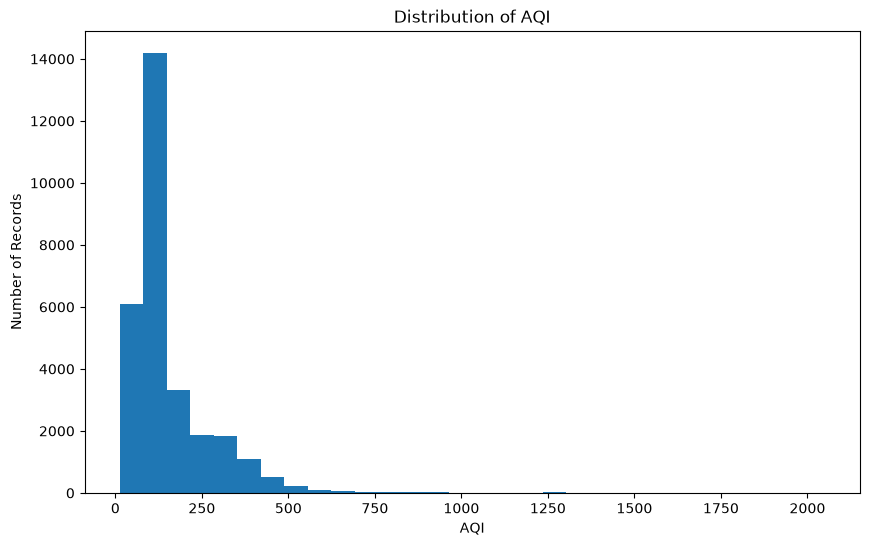

In [6]:
plt.figure(figsize=(10, 6))

plt.hist(df["aqi"].dropna(), bins=30)

plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Number of Records")

plt.show()

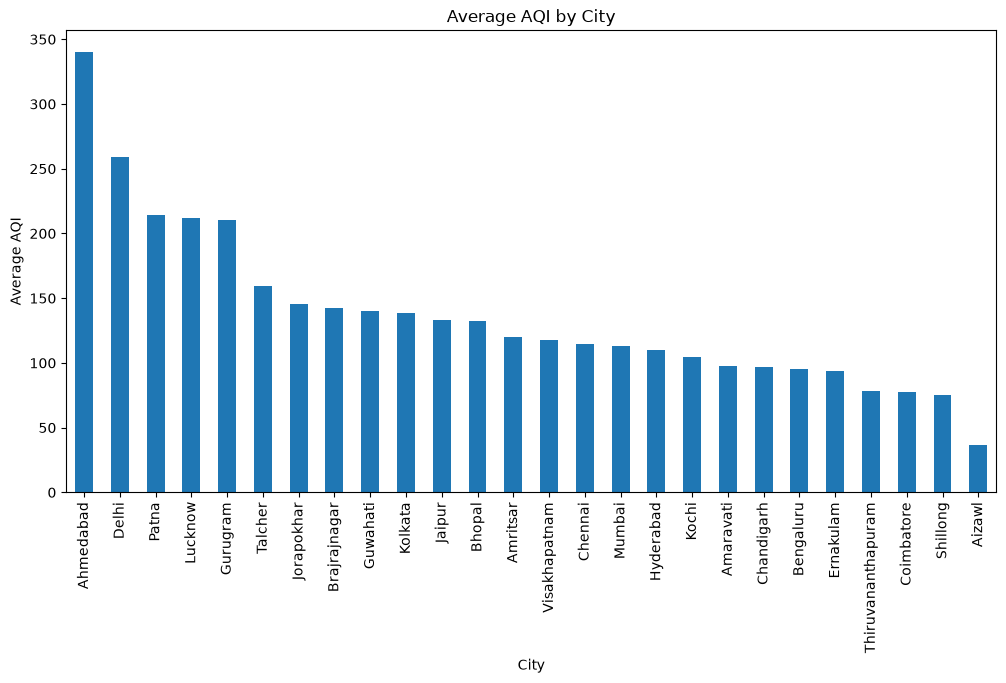

In [7]:
city_aqi = df.groupby("city")["aqi"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

city_aqi.plot(kind="bar")

plt.title("Average AQI by City")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=90)

plt.show()

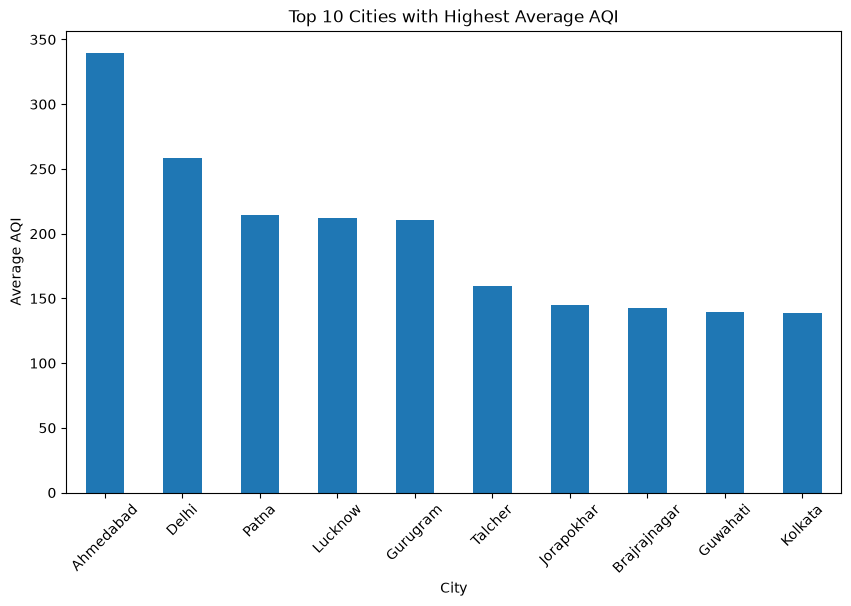

In [8]:
top_10_cities = df.groupby("city")["aqi"].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))

top_10_cities.plot(kind="bar")

plt.title("Top 10 Cities with Highest Average AQI")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)

plt.show()

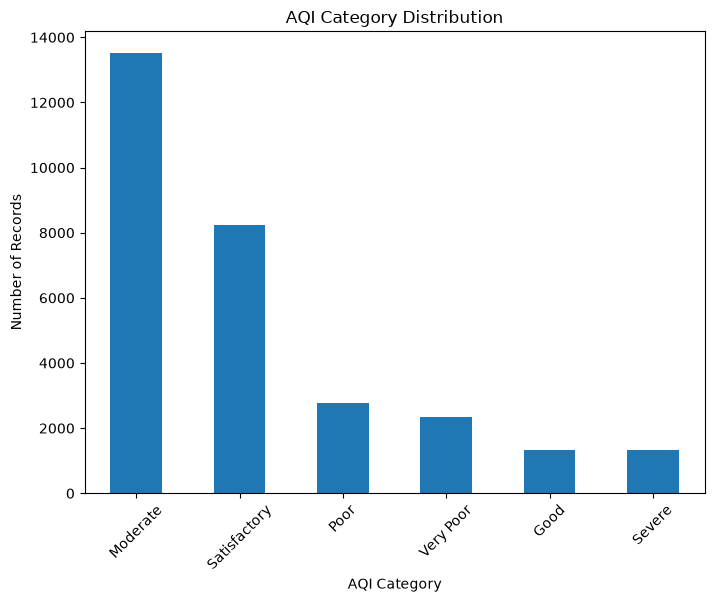

In [9]:
aqi_categories = df["aqi_bucket"].value_counts()

plt.figure(figsize=(8, 6))

aqi_categories.plot(kind="bar")

plt.title("AQI Category Distribution")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)

plt.show()

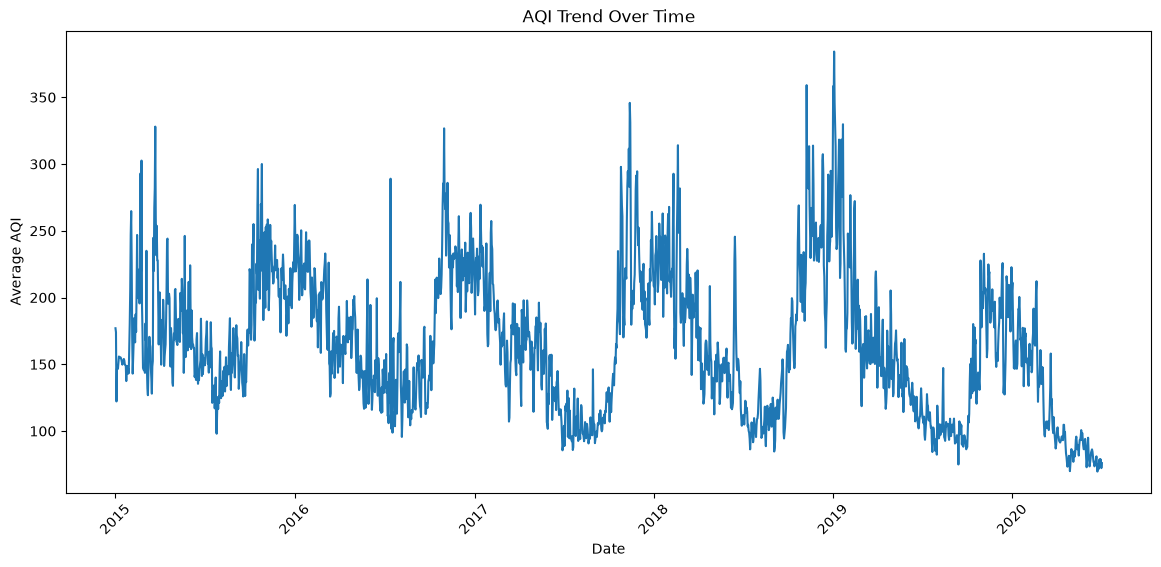

In [10]:
daily_aqi = df.groupby("date")["aqi"].mean()

plt.figure(figsize=(14, 6))

plt.plot(daily_aqi.index, daily_aqi.values)

plt.title("AQI Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Average AQI")

plt.xticks(rotation=45)

plt.show()

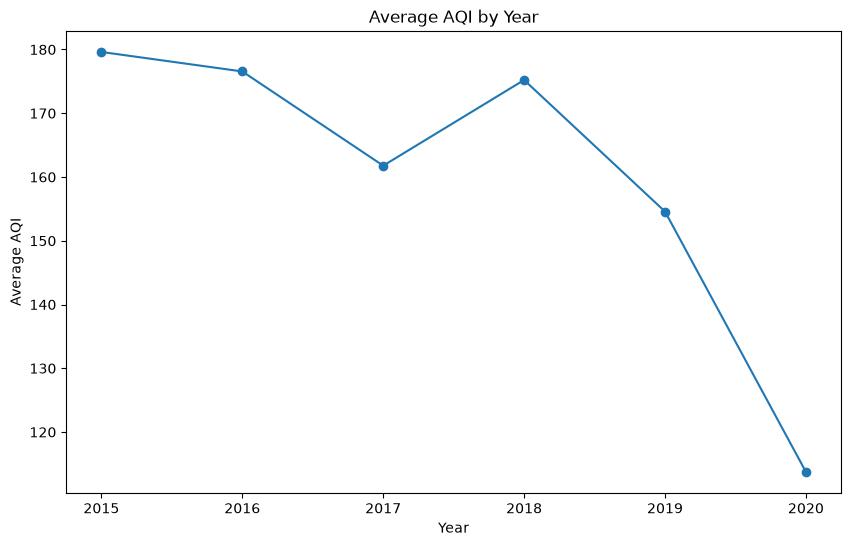

In [11]:
df["year"] = df["date"].dt.year

yearly_aqi = df.groupby("year")["aqi"].mean()

plt.figure(figsize=(10, 6))

plt.plot(yearly_aqi.index, yearly_aqi.values, marker="o")

plt.title("Average AQI by Year")
plt.xlabel("Year")
plt.ylabel("Average AQI")

plt.show()

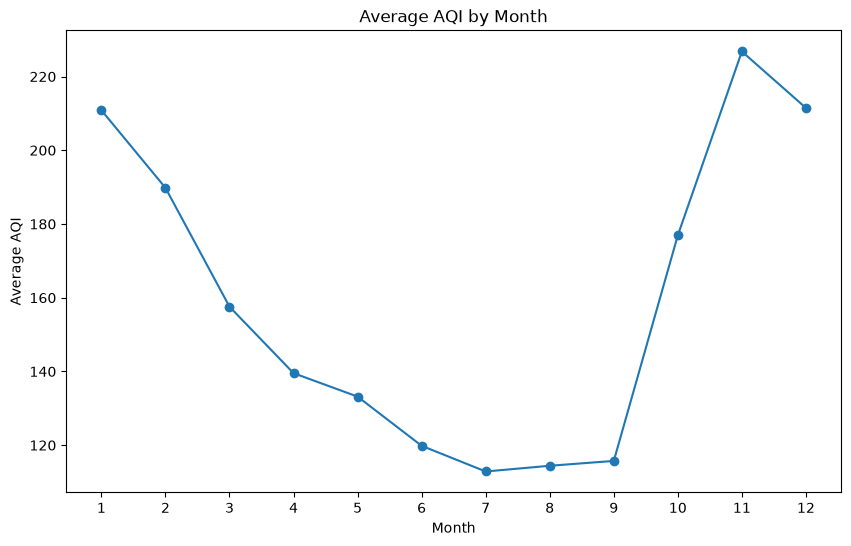

In [12]:
df["month"] = df["date"].dt.month

monthly_aqi = df.groupby("month")["aqi"].mean()

plt.figure(figsize=(10, 6))

plt.plot(monthly_aqi.index, monthly_aqi.values, marker="o")

plt.title("Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")

plt.xticks(range(1, 13))

plt.show()

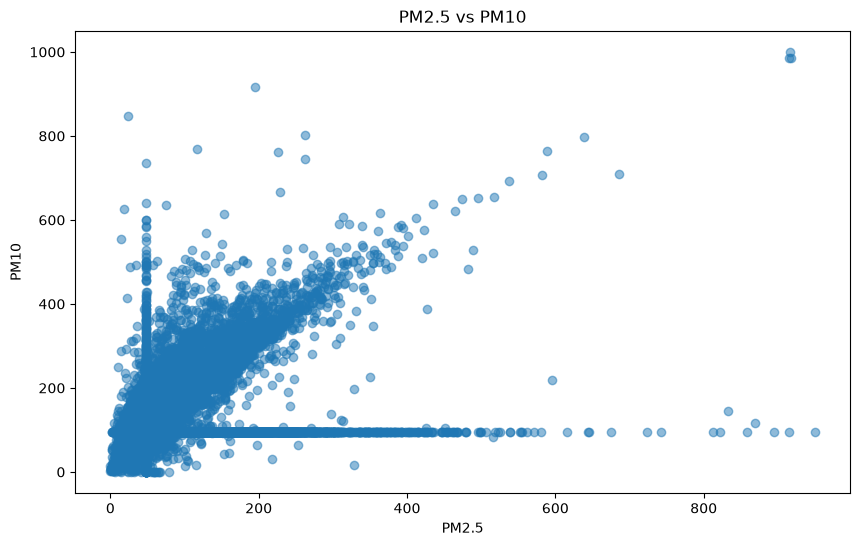

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(df["pm2.5"], df["pm10"], alpha=0.5)

plt.title("PM2.5 vs PM10")
plt.xlabel("PM2.5")
plt.ylabel("PM10")

plt.show()

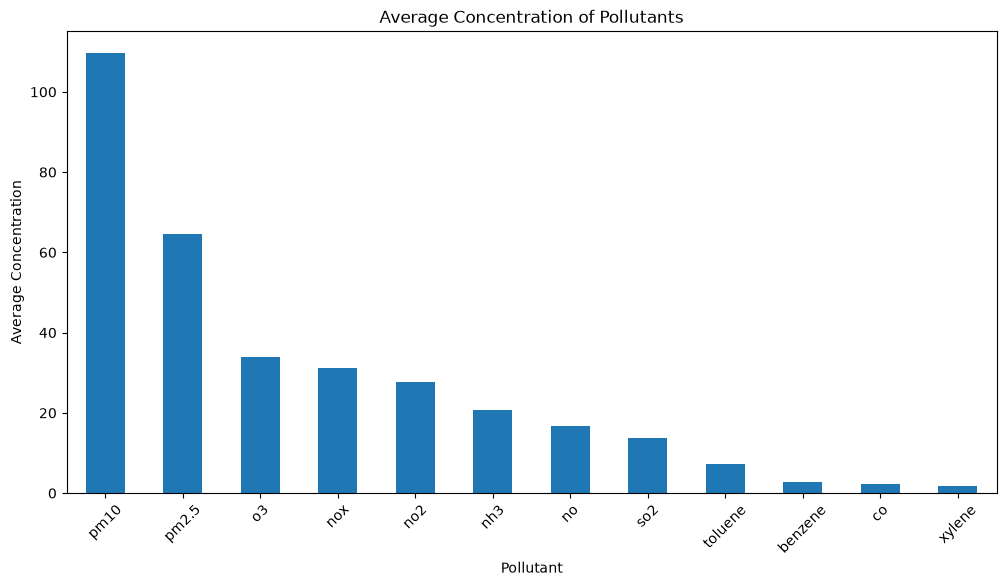

In [14]:
pollutants = [
    "pm2.5", "pm10", "no", "no2", "nox",
    "nh3", "co", "so2", "o3",
    "benzene", "toluene", "xylene"
]

pollutant_means = df[pollutants].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

pollutant_means.plot(kind="bar")

plt.title("Average Concentration of Pollutants")
plt.xlabel("Pollutant")
plt.ylabel("Average Concentration")
plt.xticks(rotation=45)

plt.show()

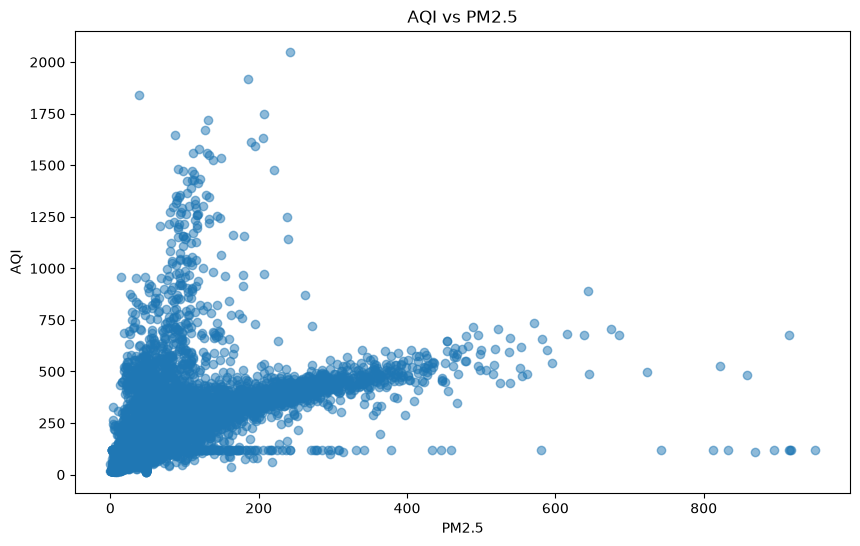

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(df["pm2.5"], df["aqi"], alpha=0.5)

plt.title("AQI vs PM2.5")
plt.xlabel("PM2.5")
plt.ylabel("AQI")

plt.show()

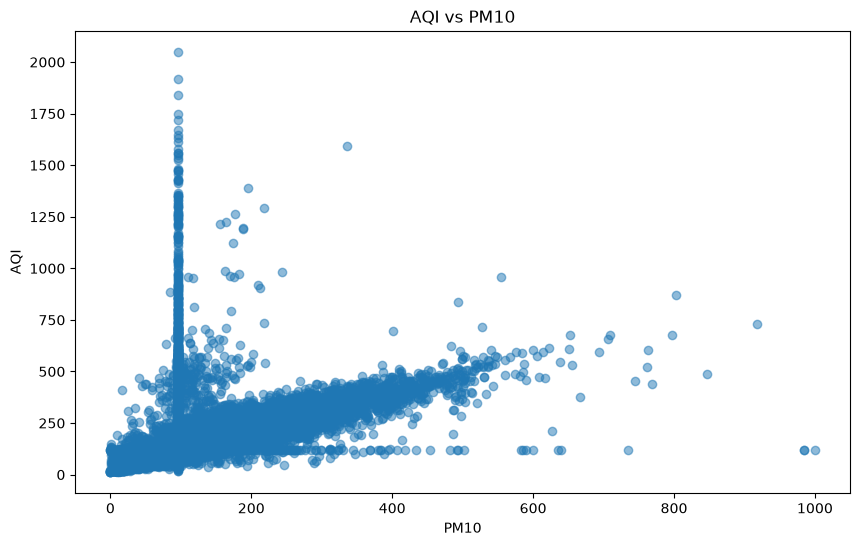

In [16]:
plt.figure(figsize=(10, 6))

plt.scatter(df["pm10"], df["aqi"], alpha=0.5)

plt.title("AQI vs PM10")
plt.xlabel("PM10")
plt.ylabel("AQI")

plt.show()

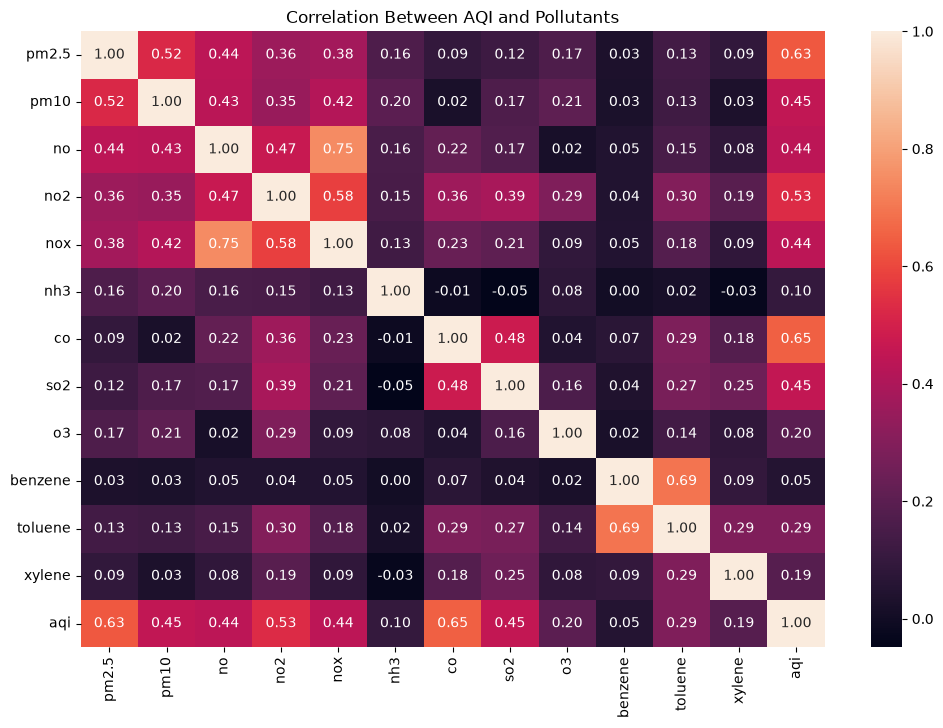

In [17]:
correlation = df[pollutants + ["aqi"]].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, fmt=".2f")

plt.title("Correlation Between AQI and Pollutants")

plt.show()

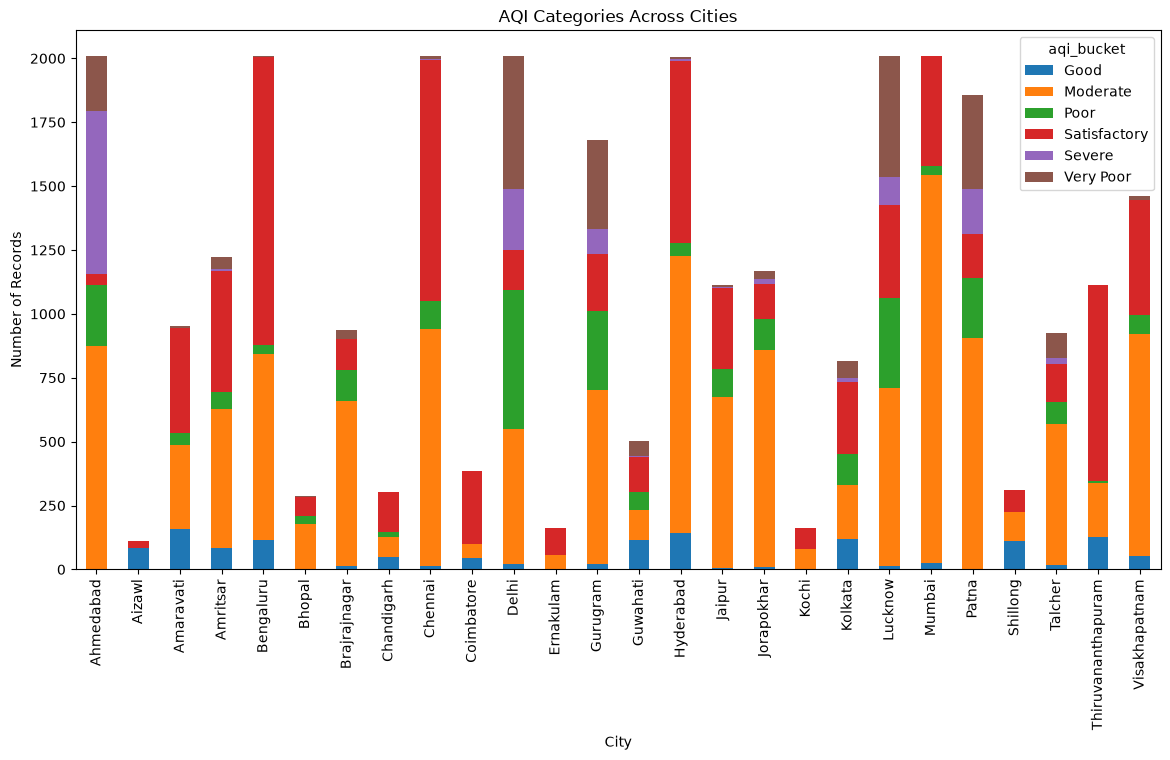

In [18]:
city_category = pd.crosstab(df["city"], df["aqi_bucket"])

city_category.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("AQI Categories Across Cities")
plt.xlabel("City")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)

plt.show()